In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

price_paths = pd.read_csv("../outputs/nba/price_paths.csv")
summary = pd.read_csv("../outputs/nba/summary.csv")

In [2]:
print("Total observations:", len(price_paths))
print("Unique markets:", price_paths["market"].nunique())
print("Unique asset IDs:", price_paths["asset_id"].nunique())

display(
    price_paths[["market", "team", "asset_id"]]
    .drop_duplicates()
    .sort_values("market")
)

Total observations: 921
Unique markets: 9
Unique asset IDs: 9


,market,team,asset_id
166,0x12c0ff4a99b3f160c77b10c8e9ab08a858bd00270de1...,Hornets,5880245859737492874022551973542316201239876351...
0,0x215be7e1cbc744ce1a85fb891db92b53f933712b5a55...,Spurs,5788147970484787294354409513715709803039667313...
86,0x24bab815e0e348358839f3bcf9d962b702610256b189...,Pacers,7911308550576651866212737748518792154163076337...
385,0x33a68692f640f9a760e9c31e8cc22c0a39d1e2164174...,Pistons,3520273085621131791294838386894657641989179274...
278,0x3659aae64ada65eb275fec0018a21a5f7242f75911de...,Jazz,7685158848984498977390071784341171138992058973...
575,0x75e1f6d6fe20e8785185c3437ff5f861049c06125707...,Kings,1129106483304658334138775472322318762529000723...
687,0xa7b7af4f22cf97db51b80d4692222b26f6d7c60209ab...,Bulls,8478232975053021656102481848967329190182250864...
490,0xa9ced0ba40242ad009b8668b13ec5269644905e86016...,Mavericks,7044837411323760085289467461482415904590124479...
801,0xcc5ffe6f0dd2ebbdae948dff2ebb541c17fb03eecd9e...,Spurs,3891772625554242753588948546535464871502402321...


In [3]:
display(
    price_paths.groupby(["market", "team"])
    .size()
    .reset_index(name="observations")
)

,market,team,observations
0,0x12c0ff4a99b3f160c77b10c8e9ab08a858bd00270de1...,Hornets,112
1,0x215be7e1cbc744ce1a85fb891db92b53f933712b5a55...,Spurs,86
2,0x24bab815e0e348358839f3bcf9d962b702610256b189...,Pacers,80
3,0x33a68692f640f9a760e9c31e8cc22c0a39d1e2164174...,Pistons,105
4,0x3659aae64ada65eb275fec0018a21a5f7242f75911de...,Jazz,107
5,0x75e1f6d6fe20e8785185c3437ff5f861049c06125707...,Kings,112
6,0xa7b7af4f22cf97db51b80d4692222b26f6d7c60209ab...,Bulls,114
7,0xa9ced0ba40242ad009b8668b13ec5269644905e86016...,Mavericks,85
8,0xcc5ffe6f0dd2ebbdae948dff2ebb541c17fb03eecd9e...,Spurs,120


In [4]:
print("Price Paths CSV:")
print(price_paths.columns.tolist())

print("\nSummary CSV:")
print(summary.columns.tolist())

Price Paths CSV:
['market', 'asset_id', 'bin', 'best_bid', 'best_ask', 'mid', 'hours_from_tip', 'variance_score', 'spread_width', 'score_margin', 'team_score', 'opponent_score', 'spread_mid', 'total_mid', 'team', 'rank', 'label', 'bucket']

Summary CSV:
['rank', 'team', 'code', 'record', 'game', 'opponent', 'tip_utc', 'pregame_std', 'in_game_std', 'pregame_price', 'won', 'spread', 'spread_pregame', 'variance_score_pregame', 'variance_score_early', 'variance_score_late', 'variance_score_live', 'minutes_to_decided', 'large_n', 'followed_n', 'led_score_n', 'espn_team_score', 'espn_opponent_score', 'espn_margin', 'game_bucket', 'final_points', 'total_line', 'total_pregame', 'note', 'opponent_code', 'pregame_n', 'in_game_n', 'spread_line', 'bid_ask_pregame', 'bid_ask_live', 'quarters', 'total_hit', 'book_size', 'book_updates', 'balance', 'volume_clob', 'score_source']


In [5]:
display(
    summary[
        ["rank", "team", "game", "opponent",
         "won", "espn_team_score", "espn_opponent_score"]
    ]
)
#missing values in won

,rank,team,game,opponent,won,espn_team_score,espn_opponent_score
0,1,Spurs,nba-sas-okc-2026-05-30,Thunder,NaN,111,103
1,2,Pacers,nba-ind-nop-2026-10-21,Pelicans,NaN,123,120
2,3,Hornets,nba-cha-bkn-2026-10-21,Nets,NaN,110,103
3,4,Jazz,nba-uta-mem-2026-10-21,Grizzlies,NaN,103,123
4,5,Pistons,nba-det-min-2026-10-14,Timberwolves,True,128,106
5,6,Mavericks,nba-dal-hou-2026-10-21,Rockets,NaN,110,128
6,7,Kings,nba-sac-lac-2026-10-21,Clippers,NaN,96,121
7,8,Bulls,nba-chi-tor-2026-10-21,Raptors,NaN,92,135
8,9,Spurs,nba-sas-nyk-2026-06-10,Knicks,False,106,107


In [6]:
import numpy as np
import pandas as pd

team_score = pd.to_numeric(summary["espn_team_score"], errors="coerce")
opponent_score = pd.to_numeric(summary["espn_opponent_score"], errors="coerce")

# determine winner
summary["won"] = np.select(
    [
        team_score > opponent_score,
        team_score < opponent_score
    ],
    [
        summary["team"],
        summary["opponent"]
    ],
    default=None
)

display(
    summary[
        ["team", "opponent", "espn_team_score",
         "espn_opponent_score", "won"]
    ]
)

,team,opponent,espn_team_score,espn_opponent_score,won
0,Spurs,Thunder,111,103,Spurs
1,Pacers,Pelicans,123,120,Pacers
2,Hornets,Nets,110,103,Hornets
3,Jazz,Grizzlies,103,123,Grizzlies
4,Pistons,Timberwolves,128,106,Pistons
5,Mavericks,Rockets,110,128,Rockets
6,Kings,Clippers,96,121,Clippers
7,Bulls,Raptors,92,135,Raptors
8,Spurs,Knicks,106,107,Knicks


In [7]:
# Merge the actual winner into each price observation
df = price_paths.merge(
    summary[["rank", "team", "won", "tip_utc"]],
    on=["rank", "team"],
    how="left",
    validate="many_to_one"
)

df["bin"] = pd.to_datetime(df["bin"], utc=True)
df["tip_utc"] = pd.to_datetime(df["tip_utc"], utc=True)

# Whether the team represented by this market won
df["team_won"] = df["team"] == df["won"]

# Missing winner names should remain unknown
df.loc[df["won"].isna(), "team_won"] = pd.NA
df["team_won"] = df["team_won"].astype("boolean")

display(
    df[["rank", "team", "won", "team_won", "bin", "mid"]].head()
)

/var/folders/mx/v59wd7dx16vgn3jfq68n30840000gn/T/ipykernel_24383/3457575801.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df.loc[df["won"].isna(), "team_won"] = pd.NA


,rank,team,won,team_won,bin,mid
0,1,Spurs,Spurs,True,2026-05-30 20:00:00+00:00,0.4250
1,1,Spurs,Spurs,True,2026-05-30 20:05:00+00:00,0.4250
2,1,Spurs,Spurs,True,2026-05-30 20:10:00+00:00,0.4250
3,1,Spurs,Spurs,True,2026-05-30 20:15:00+00:00,0.4250
4,1,Spurs,Spurs,True,2026-05-30 20:20:00+00:00,0.4250


In [8]:
df["correct_outcome_price"] = np.where(
    df["team_won"].astype(bool),
    df["mid"],
    1 - df["mid"]
)

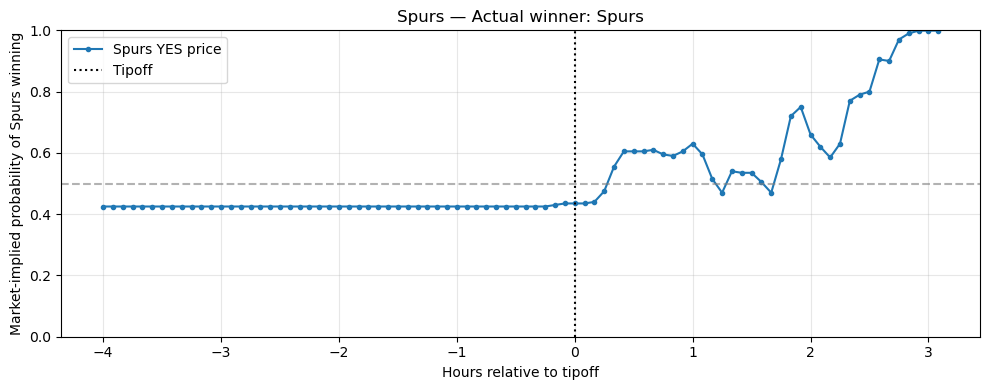

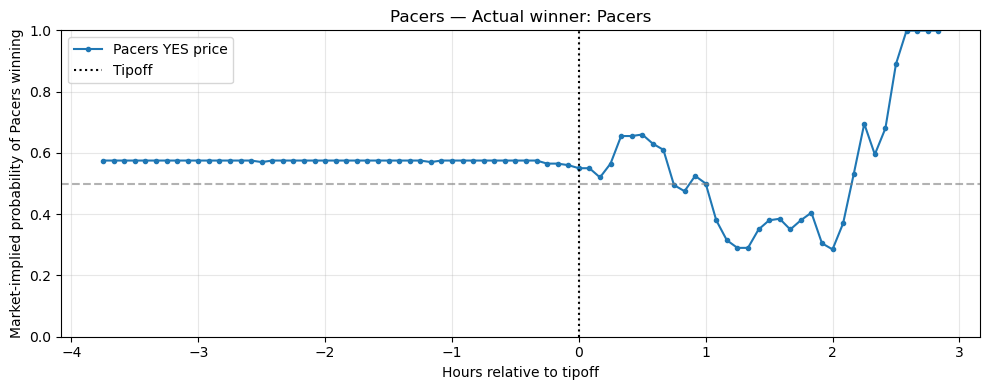

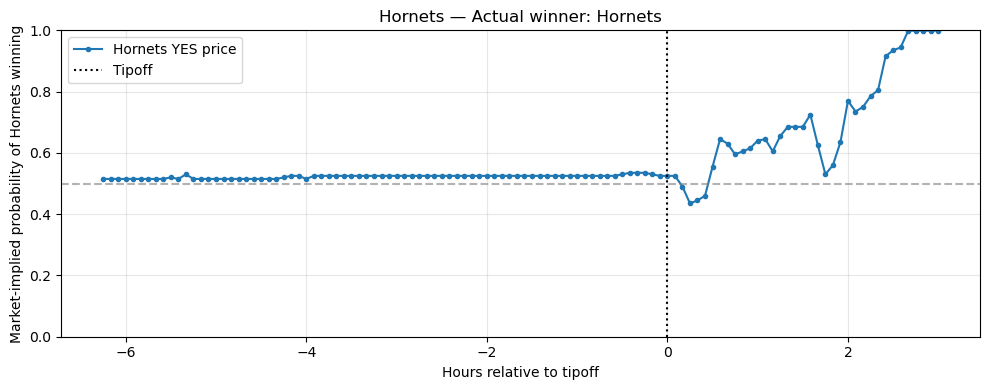

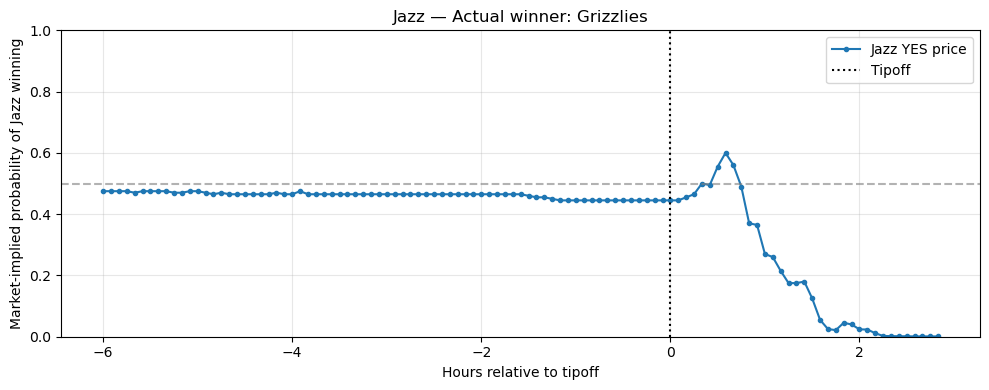

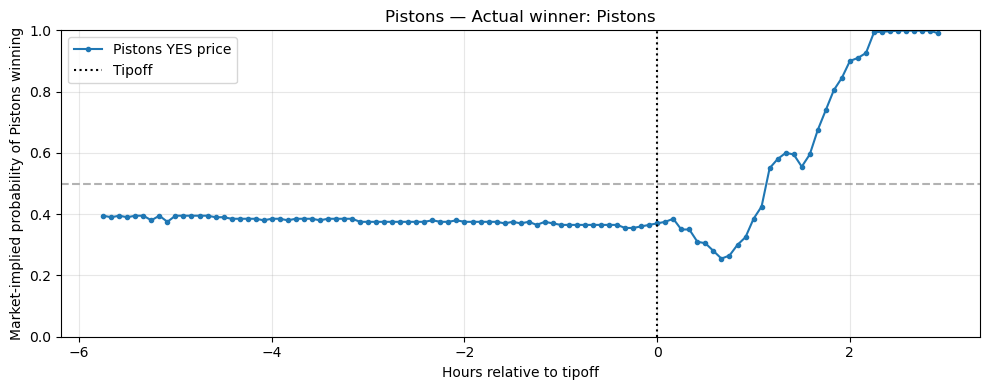

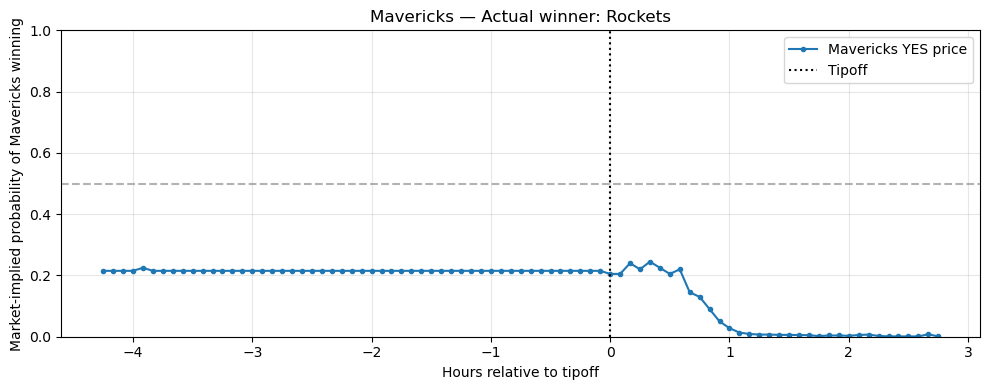

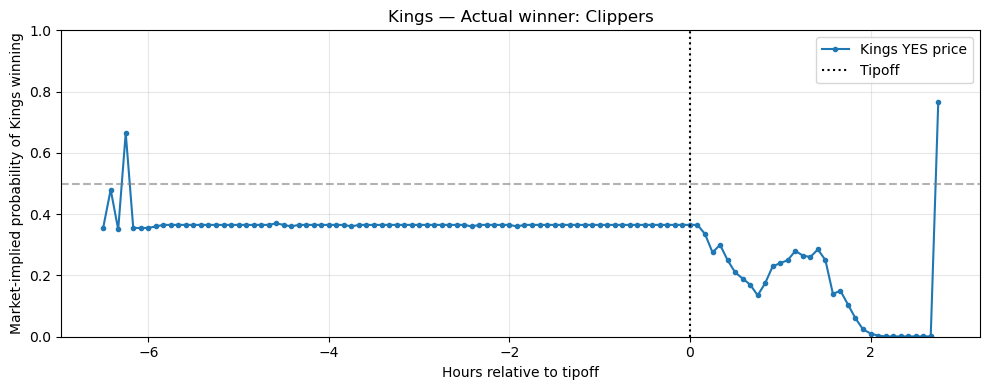

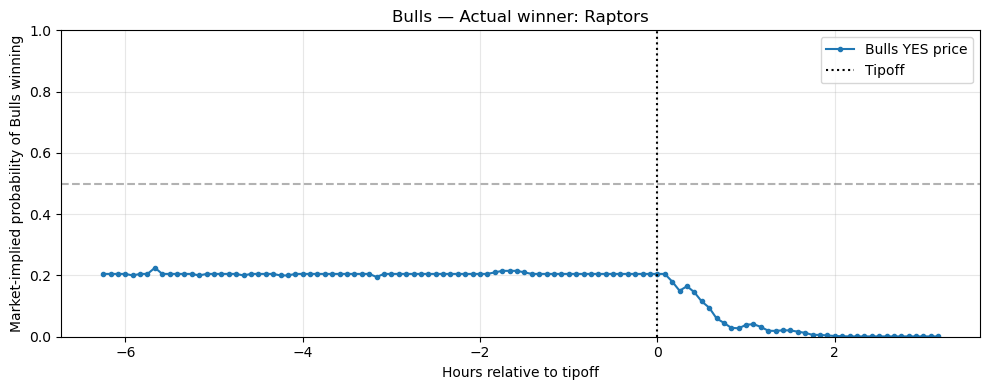

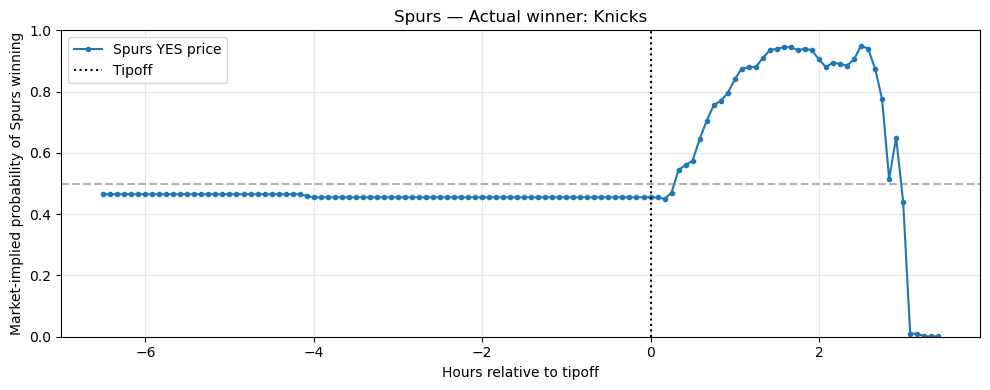

All plots saved to: /Users/victoriavu25/414Midterm/outputs/nba/victorias_figures


In [9]:
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("../outputs/nba/victorias_figures")
output_dir.mkdir(parents=True, exist_ok=True)

for (rank, team), group in df.groupby(["rank", "team"]):
    group = group.sort_values("bin")

    plt.figure(figsize=(10, 4))

    # Always plot the tracked team's YES price
    plt.plot(
        group["hours_from_tip"],
        group["mid"],
        marker=".",
        linewidth=1.5,
        label=f"{team} YES price"
    )

    plt.axhline(0.5, color="gray", linestyle="--", alpha=0.6)
    plt.axvline(0, color="black", linestyle=":", label="Tipoff")

    plt.title(f"{team} — Actual winner: {group['won'].iloc[0]}")
    plt.xlabel("Hours relative to tipoff")
    plt.ylabel(f"Market-implied probability of {team} winning")

    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = f"{rank}_{team.lower().replace(' ', '_')}_price.png"
    plt.savefig(output_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()

print(f"All plots saved to: {output_dir.resolve()}")